# Type I seesaw with one active and one sterile neutrino — complex $m_D$ (Takagi factorization)

With a complex Dirac mass, $m_D=r\,e^{i\phi_r}$, the matrix

$$M=\begin{pmatrix}0 & r e^{i\phi_r}\\ r e^{i\phi_r} & M_1\end{pmatrix}$$

is complex symmetric, not Hermitian, so its eigenvalues are not the masses. The masses are its singular values, i.e. the square roots of the eigenvalues of $M^\dagger M$, and the mixing matrix is the unitary $U$ of the Takagi factorization $U^TMU=\mathrm{diag}(m_1,m_2)$.

**Assumptions**

* $r>0$, $\phi_r\in\mathbb{R}$, $M_1>0$ (sterile basis choice), $m_1<m_2$.

**Result of this notebook:** the phase $\phi_r$ is unphysical. In general $n(m-1)$ phases of $m_D$ survive the rephasing of the $n$ active fields, which is zero for any $(n,1)$ case. The complex one-generation problem is the real one (`seesaw_one_generation.ipynb`) times a rephasing of $\nu_L$.

In [1]:
import os
import sys

# Make the ``src`` package importable (the notebook lives in ``notebooks/``)
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.insert(0, project_root)

import numpy as np
import sympy as sp
from sympy import (symbols, solve, sin, cos, tan, sqrt, exp, I, pi, Matrix,
                   conjugate, factor, simplify, init_printing)

from src.seesaw import SymbolicSeesawTypeI
from src.matrix_utils import (symbolic_rotation_matrix, sin_cos_from_tan_fraction,
                              simplify_with_mass_ordering, seesaw_block_expansion,
                              takagi_factorization)
from src.symbolic_diagonalization import *

init_printing()

## 1. Mass matrix and $M^\dagger M$

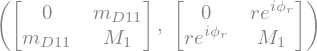

In [2]:
seesaw = SymbolicSeesawTypeI(n_generations=1, n_sterile=1, majorana_basis='diagonal')
mD = seesaw.m_D_sym[0, 0]          # generic complex symbol
M1 = seesaw.M_R_sym[0, 0]
m1, m2 = seesaw.massive_masses
r = symbols('r', positive=True)
phir = symbols(r'\phi_r', real=True)
polar = {mD: r*exp(I*phir)}
Mnu2x2 = seesaw.full_mass_matrix_symbolic()
Mnu2x2, Mnu2x2.subs(polar)

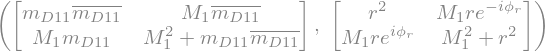

In [3]:
MnuDaggerMnu2x2 = seesaw.MDaggerM()
MnuDaggerMnu2x2, MnuDaggerMnu2x2.subs(polar).applyfunc(simplify)

## 2. Characteristic polynomial of $M^\dagger M$ and the inverse problem

The polynomial is quadratic in $\lambda=m^2$; its coefficients depend on $m_D$ only through $|m_D|^2$, so the masses cannot depend on the phase.

In [4]:
charpoly_relations = seesaw.charpoly_relations_MDaggerM()
charpoly_relations['char_poly_M'], charpoly_relations['char_poly_diag']

In [5]:
eqs_charpoly = [
    charpoly_relations['coefficients_full_matrix'][key] - charpoly_relations['coefficients_diagonal'][key]
    for key in charpoly_relations['coefficients_full_matrix']
]
eqs_charpoly

In [6]:
seesaw_parameters_sols = solve(eqs_charpoly, mD*conjugate(mD), M1**2, dict=True)
seesaw_parameters_sols

Only the solution with $|m_D|^2=m_1m_2>0$ is acceptable, and $M_1>0$ with $m_1<m_2$ selects $M_1=m_2-m_1$:

In [7]:
seesaw_sol = [sol for sol in seesaw_parameters_sols if sol[mD*conjugate(mD)].is_positive][0]
r_sol = {r: sqrt(seesaw_sol[mD*conjugate(mD)])}
MR_sol = {M1: m2 - m1}
(simplify_with_mass_ordering(seesaw_sol[M1**2] - MR_sol[M1]**2, seesaw.masses), r_sol, MR_sol)

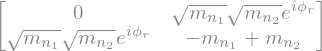

In [8]:
Mnu2x2_masses = Mnu2x2.subs(polar).subs(r_sol).subs(MR_sol)
Mnu2x2_masses

## 3. Direct Takagi factorization

`direct_diagonalization` solves $\det(\lambda-M^\dagger M)=0$, takes the eigenvectors $u_i$ of $M^\dagger M$ and rephases each one so that $M u_i=m_i u_i^*$.

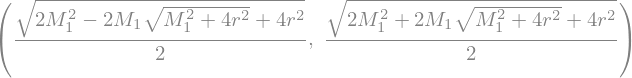

In [9]:
direct = direct_diagonalization(seesaw)
m1_direct, m2_direct = [simplify(mass.subs(polar)) for mass in direct['masses']]
m1_direct, m2_direct

These are $m_{1,2}=\tfrac12\left(\sqrt{M_1^2+4r^2}\mp M_1\right)$, as in the real case with $m_D\to r$ (product, sum of squares, and difference of squares with respect to that form):

In [10]:
masses_real = [(sqrt(M1**2 + 4*r**2) - M1)/2, (sqrt(M1**2 + 4*r**2) + M1)/2]
(simplify(m1_direct*m2_direct), simplify(m1_direct**2 + m2_direct**2),
 [simplify(m1_direct**2 - masses_real[0]**2), simplify(m2_direct**2 - masses_real[1]**2)])

In [11]:
verify_takagi(direct['U'], Mnu2x2, direct['masses'])

{'passed': True,
 'diagonalization_error': 3.0749768513990206e-16,
 'unitarity_error': 8.881784197001252e-16,
 'mass_error': 2.486353590973258e-16,
 'n_points': 5,
 'precision': 'double'}

## 4. The phase is a rephasing of $\nu_L$

With $\Phi=\mathrm{diag}(e^{i\phi_r},1)$ one has $M(\phi_r)=\Phi\,M(0)\,\Phi$, so if $U_0$ diagonalizes the real matrix $M(0)$ then $U=\Phi^{*}U_0$ diagonalizes $M(\phi_r)$.

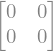

In [12]:
Phi = sp.diag(exp(I*phir), 1)
Mnu2x2_real = Mnu2x2.subs(mD, r)
(Phi*Mnu2x2_real*Phi - Mnu2x2.subs(polar)).applyfunc(simplify)

The real problem is solved by a rotation (as in `seesaw_one_generation.ipynb`) times the Majorana phase matrix $P=\mathrm{diag}(i,1)$:

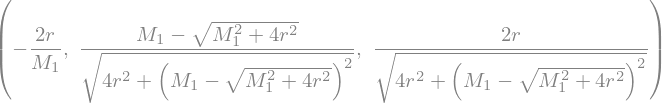

In [13]:
th = symbols('theta', real=True)
Rth = symbolic_rotation_matrix(dim=2, axis=1, angle=th)
Mnu2x2_diag = (Rth.T*Mnu2x2_real*Rth).applyfunc(lambda x: x.trigsimp())
sin2th_sol = solve(Mnu2x2_diag[0, 1], sin(2*th), dict=True)[0]
tan2th = sin2th_sol[sin(2*th)]/cos(2*th)
sin2th, cos2th = sin_cos_from_tan_fraction(tan2th)
tanth = ((1 - cos2th)/sin2th).factor()
sinth, costh = sin_cos_from_tan_fraction(tanth)
tan2th, sinth, costh

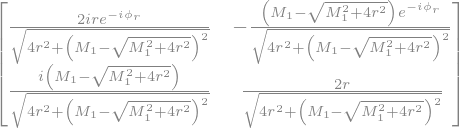

In [14]:
P = majorana_phase_matrix([-1, 1])
U0 = Rth.subs({sin(th): sinth, cos(th): costh})*P
U_takagi = Phi.conjugate()*U0
U_takagi

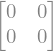

In [15]:
(U_takagi.T*Mnu2x2.subs(polar)*U_takagi - sp.diag(*masses_real)).applyfunc(simplify)

In terms of the masses ($r=\sqrt{m_1m_2}$, $M_1=m_2-m_1$):

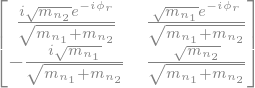

In [16]:
U_masses = simplify_with_mass_ordering(U_takagi.subs(r_sol).subs(MR_sol), seesaw.masses)
U_masses

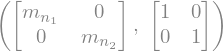

In [17]:
((U_masses.T*Mnu2x2_masses*U_masses).applyfunc(simplify), (U_masses.H*U_masses).applyfunc(simplify))

The phase $\phi_r$ only multiplies the $\nu_L$ row of $U$. In the charged-current interaction it is absorbed by the charged-lepton field, so no observable depends on it. The physical content is $\tan^2\theta=m_1/m_2$ and the relative Majorana phase $i$ between the two columns.

## 5. Numerical verification

In [18]:
verify_takagi(U_takagi, Mnu2x2.subs(polar), masses_real, ranges={phir: (-3.1, 3.1)})

{'passed': True,
 'diagonalization_error': 1.5272909223533008e-16,
 'unitarity_error': 1.1102230246251565e-16,
 'mass_error': 3.0512315010498993e-16,
 'n_points': 5,
 'precision': 'double'}

In [19]:
verify_takagi(U_masses, Mnu2x2_masses, [m1, m2],
              ranges={m1: (0.01, 0.5), m2: (1.0, 5.0), phir: (-3.1, 3.1)})

{'passed': True,
 'diagonalization_error': 2.1732887137258803e-16,
 'unitarity_error': 2.220446049250313e-16,
 'mass_error': 3.1641028102977597e-16,
 'n_points': 5,
 'precision': 'double'}

## Summary

| quantity | exact result |
|:--|:--|
| squared masses | roots of $\lambda^2-(M_1^2+2r^2)\lambda+r^4$ |
| invariants | $m_1m_2=|m_D|^2$, $\;m_2-m_1=M_1$ |
| Takagi matrix | $U=\mathrm{diag}(e^{-i\phi_r},1)\,R(\theta)\,\mathrm{diag}(i,1)$, $\;\tan^2\theta=m_1/m_2$ |
| physical phases | none ($n(m-1)=0$) |